### Libreta para EDA ya usando los datos almacenados en Parquet

In [136]:
import pandas as pd
import numpy as np
from datetime import date
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import re

In [137]:
def leer_archivos_de_un_anio(direccion, anio):
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob(f"*_{anio}_*.parquet")
        ],
        ignore_index=True
    )

    return df

In [138]:
def leer_todos_los_archivos(direccion):
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob("*.parquet")
        ],
        ignore_index=True
    )

    return df

In [139]:
def leer_rango(direccion, desde=(2014, 12), hasta=(9999, 12), columnas=None):
    patron = re.compile(r"datos_abiertos_(\d{4})_(\d{2})\.parquet$")
    archivos = []
    for ruta in sorted(Path(direccion).glob("datos_abiertos_*.parquet")):
        m = patron.search(ruta.name)
        if m and desde <= (int(m[1]), int(m[2])) <= hasta:
            archivos.append(ruta)
    if not archivos:
        raise FileNotFoundError(f"No hay Parquet entre {desde} y {hasta} en '{direccion}'")
    
    df = pd.concat(
        [
            pd.read_parquet(r, columns=columnas).assign(nombre_archivo=r.name) for r in archivos
        ],
        ignore_index=True)

    return df

In [140]:
def redondear_a_primer_dia_del_mes(dt_col):
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

In [141]:
DATA_DIR = "../data/external"
df = leer_todos_los_archivos(DATA_DIR)

In [142]:
df = leer_rango(DATA_DIR, (2020, 1), (2026, 9))

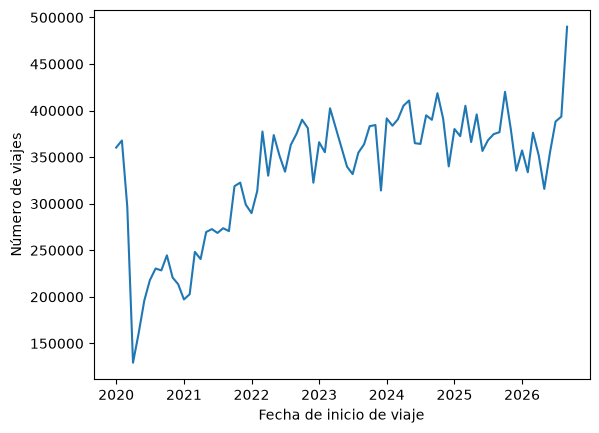

In [143]:
df["mes_redondeado"] = redondear_a_primer_dia_del_mes(df["inicio_del_viaje"])
groupedby = df.groupby(df["mes_redondeado"])['viaje_id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

In [144]:
# Solo Genero y Año de nacimiento tienen nulls
# Pendiente revisar si hay strings actuando como nulos
df.isna().sum()

viaje_id                   0
usuario_id                 0
genero                135232
anio_de_nacimiento     33796
inicio_del_viaje           0
fin_del_viaje              0
origen_id                  0
destino_id                 0
nombre_archivo             0
mes_redondeado             0
dtype: int64

In [145]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["genero","anio_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

,genero,anio_de_nacimiento
genero,1.000000,0.058628
anio_de_nacimiento,0.058628,1.000000


In [146]:
# 29779602 records no tienen ninguna de estas columnas (Genero, Año de nacimiento) nulas
# 165406 tienen una u otra nula
# 7477 tienen ambas nulas
null_matrix.sum(axis=1).value_counts()

0    26224258
1      160780
2        4124
Name: count, dtype: int64

In [147]:
# Los ids no se deben analizar como numéricos (absurdamente ineficiente, no hacer esto en prod)
# Solo es para usar bien los describe() por ahora
id_cols = ["viaje_id", "usuario_id", "origen_id", "destino_id"]
df[id_cols] = df[id_cols].astype(str)

In [148]:
cat_cols = df.select_dtypes(include=["str","object"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

In [149]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2020_02 (justo antes del inicio de la pandemia) es el que tiene más records (del 2020 en adelante)
# No todos los viajes son únicos, algunos Ids se duplican
# 72% de los registros son de hombres

,count,unique,top,freq
viaje_id,26389162,26388404,45705948,2
usuario_id,26389162,81115,51332,15868
genero,26253930,2,M,19130897
origen_id,26389162,475,51,552081
destino_id,26389162,475,51,697952
nombre_archivo,26389162,79,datos_abiertos_2026_09.parquet,490056


In [150]:
df["genero"].value_counts()*100/len(df)

genero
M    72.495280
F    26.992267
Name: count, dtype: float64

In [151]:
# Qué ocurre cuando Genero es nulo?
df[df["genero"].isnull()].head(100)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,mes_redondeado
230,14420499,634722,NaN,<NA>,2020-01-01 10:00:48,2020-01-01 10:16:46,77,36,datos_abiertos_2020_01.parquet,2020-01-01
334,14420610,634711,NaN,<NA>,2020-01-01 10:49:31,2020-01-01 11:05:36,28,56,datos_abiertos_2020_01.parquet,2020-01-01
335,14420611,634711,NaN,<NA>,2020-01-01 10:49:37,2020-01-01 11:05:24,28,56,datos_abiertos_2020_01.parquet,2020-01-01
368,14420644,634725,NaN,<NA>,2020-01-01 10:59:51,2020-01-01 11:14:58,198,50,datos_abiertos_2020_01.parquet,2020-01-01
378,14420654,634722,NaN,<NA>,2020-01-01 11:04:27,2020-01-01 11:25:08,36,34,datos_abiertos_2020_01.parquet,2020-01-01
...,...,...,...,...,...,...,...,...,...,...
26890,14453499,635541,NaN,<NA>,2020-01-05 10:30:26,2020-01-05 10:43:53,133,221,datos_abiertos_2020_01.parquet,2020-01-01
26891,14453500,635541,NaN,<NA>,2020-01-05 10:30:30,2020-01-05 10:44:45,133,221,datos_abiertos_2020_01.parquet,2020-01-01
26901,14453510,635544,NaN,<NA>,2020-01-05 10:31:38,2020-01-05 10:45:57,196,50,datos_abiertos_2020_01.parquet,2020-01-01
26916,14453525,635552,NaN,<NA>,2020-01-05 10:33:33,2020-01-05 12:19:07,194,194,datos_abiertos_2020_01.parquet,2020-01-01


In [152]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df

# Año de nacimiento mínimo de 1 está muy raro
# Año de nacimiento máximo de 2023 también

,count,mean,std,min,25%,50%,75%,max,kurt,skew
anio_de_nacimiento,26355366.0,1989.057583,17.043063,1.0,1984.0,1992.0,1997.0,2023.0,7575.476138,-67.445369


In [153]:
# Se quitan los datos donde el año de nacimiento es menor a 1900
df = df[df["anio_de_nacimiento"] >= 1900]

In [154]:
# Solo hay 3 años de nacimiento distintos mayores a 2010
df[df["anio_de_nacimiento"] > 2010].anio_de_nacimiento.value_counts()

anio_de_nacimiento
2023    1151
2021     568
2022     374
Name: count, dtype: Int64

In [155]:
# Para evaluar estos registros se toma un approach diferente
# se estima la edad aproximada de la persona cuando ocurrió el viaje
df["edad_aproximada"] = df["inicio_del_viaje"].dt.year - df["anio_de_nacimiento"]

In [156]:
# Todos los que pudieran tener una edad de 5 años o menos, tienen entre 0 y 2 años
df[df["edad_aproximada"] < 6].edad_aproximada.value_counts()

edad_aproximada
1    1095
0     569
2     429
Name: count, dtype: Int64

In [157]:
# Por lo tanto, se interpretan como records erroneos y se eliminan
df = df[df["edad_aproximada"] > 5]

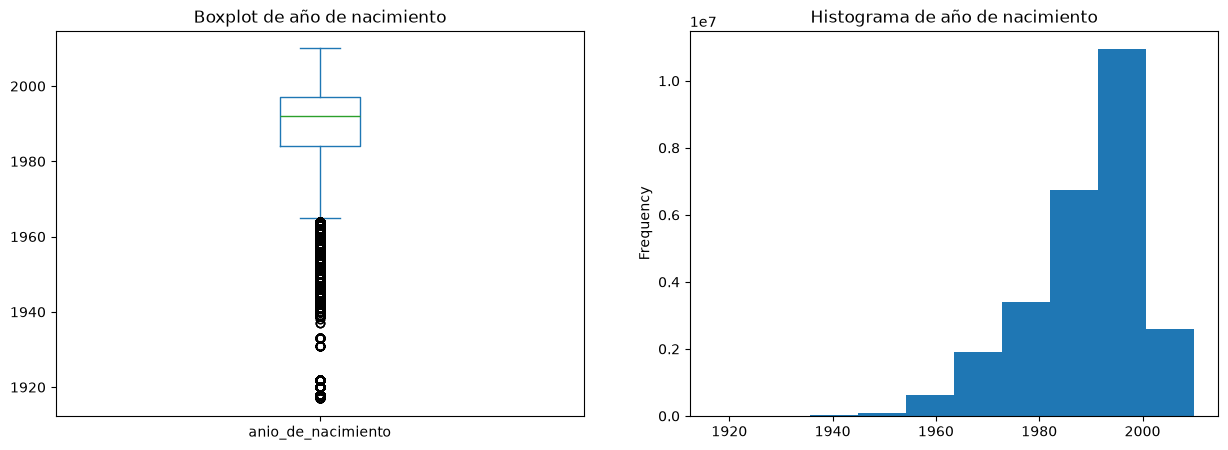

In [158]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
df.anio_de_nacimiento.plot.box()
plt.title("Boxplot de año de nacimiento")

plt.subplot(1,2,2)
df.anio_de_nacimiento.plot.hist()
plt.title("Histograma de año de nacimiento")

plt.show()

In [159]:
df

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,mes_redondeado,edad_aproximada
0,14420217,451617,M,1992,2020-01-01 06:02:20,2020-01-01 06:05:38,52,268,datos_abiertos_2020_01.parquet,2020-01-01,28
1,14420218,324211,M,1985,2020-01-01 06:02:22,2020-01-01 06:07:32,254,180,datos_abiertos_2020_01.parquet,2020-01-01,35
2,14420219,611633,M,1981,2020-01-01 06:03:01,2020-01-01 06:21:43,258,278,datos_abiertos_2020_01.parquet,2020-01-01,39
3,14420220,521601,M,1989,2020-01-01 06:05:48,2020-01-01 06:15:11,200,201,datos_abiertos_2020_01.parquet,2020-01-01,31
4,14420221,631227,M,1979,2020-01-01 06:08:15,2020-01-01 06:29:33,151,248,datos_abiertos_2020_01.parquet,2020-01-01,41
...,...,...,...,...,...,...,...,...,...,...,...
26389157,46255554,116275,F,1990,2026-09-30 23:57:23,2026-09-30 23:59:46,43,44,datos_abiertos_2026_09.parquet,2026-09-01,36
26389158,46255556,4621160,M,1970,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,datos_abiertos_2026_09.parquet,2026-09-01,56
26389159,46255556,4621160,M,1970,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,datos_abiertos_2026_09.parquet,2026-09-01,56
26389160,46255557,4560372,M,1987,2026-09-30 23:59:32,2026-10-01 00:06:16,157,271,datos_abiertos_2026_09.parquet,2026-09-01,39


In [160]:
nom_df = pd.read_csv("../data/external/nomenclatura_estaciones.csv")

In [161]:
nom_df

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11
...,...,...,...,...,...
479,515,(GDL-295) C. Tarahumaras / Av. Manuel Acuña,20.684117,-103.394360,15
480,516,(ZPN-105) Av. Atemajac/Colinas del Congreso,20.721205,-103.365756,19
481,517,(ZPN-106) Av. Atemajac/Colinas del Capitolio,20.720910,-103.362985,19
482,518,(ZPN-108) Av. Atemajac / Av. Yermo y Parra,20.721377,-103.368757,19


In [ ]:
# Si un id no está en el archivo de la nomenclatura, no es posible analizarlo para el problema P2. Los records con estos ids se eliminan
def descartar_records_con_id_inexistente_en_nomenclatura(datos_df, nomenclatura_df, col_origen, col_destino, col_id_nomenclatura):
    origen_id_no_en_nomenclatura = ~(datos_df[col_origen].isin(nomenclatura_df[col_id_nomenclatura].unique().astype(str)))
    destino_id_no_en_nomenclatura = ~(datos_df[col_destino].isin(nomenclatura_df[col_id_nomenclatura].unique().astype(str)))
    return datos_df[~(origen_id_no_en_nomenclatura | destino_id_no_en_nomenclatura)]

In [164]:
df = descartar_records_con_id_inexistente_en_nomenclatura(df, nom_df, "origen_id", "destino_id", "id")

In [165]:
df

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,mes_redondeado,edad_aproximada
0,14420217,451617,M,1992,2020-01-01 06:02:20,2020-01-01 06:05:38,52,268,datos_abiertos_2020_01.parquet,2020-01-01,28
1,14420218,324211,M,1985,2020-01-01 06:02:22,2020-01-01 06:07:32,254,180,datos_abiertos_2020_01.parquet,2020-01-01,35
2,14420219,611633,M,1981,2020-01-01 06:03:01,2020-01-01 06:21:43,258,278,datos_abiertos_2020_01.parquet,2020-01-01,39
3,14420220,521601,M,1989,2020-01-01 06:05:48,2020-01-01 06:15:11,200,201,datos_abiertos_2020_01.parquet,2020-01-01,31
4,14420221,631227,M,1979,2020-01-01 06:08:15,2020-01-01 06:29:33,151,248,datos_abiertos_2020_01.parquet,2020-01-01,41
...,...,...,...,...,...,...,...,...,...,...,...
26389157,46255554,116275,F,1990,2026-09-30 23:57:23,2026-09-30 23:59:46,43,44,datos_abiertos_2026_09.parquet,2026-09-01,36
26389158,46255556,4621160,M,1970,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,datos_abiertos_2026_09.parquet,2026-09-01,56
26389159,46255556,4621160,M,1970,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,datos_abiertos_2026_09.parquet,2026-09-01,56
26389160,46255557,4560372,M,1987,2026-09-30 23:59:32,2026-10-01 00:06:16,157,271,datos_abiertos_2026_09.parquet,2026-09-01,39


In [170]:
df["duracion_del_viaje"] = (df.fin_del_viaje - df.inicio_del_viaje).dt.total_seconds()

In [175]:
df["duracion_del_viaje"].sort_values(ascending=False)

3292526     1689046.0
108473      1487001.0
4042178     1456986.0
3897347     1039488.0
2380157      840784.0
              ...    
13241055          0.0
14921526          0.0
17207430          0.0
8602122           0.0
14619750          0.0
Name: duracion_del_viaje, Length: 26348057, dtype: float64

In [178]:
df[df["duracion_del_viaje"] > 60*60*24].sort_values(by="duracion_del_viaje", ascending=False)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,mes_redondeado,edad_aproximada,duracion_del_viaje
3292526,18537759,626320,M,1997,2021-03-03 20:57:57,2021-03-23 10:08:43,180,75,datos_abiertos_2021_03.parquet,2021-03-01,24,1689046.0
108473,14551302,363347,F,1986,2020-01-13 07:06:24,2020-01-30 12:09:45,230,227,datos_abiertos_2020_01.parquet,2020-01-01,34,1487001.0
4042178,19426506,563734,M,1988,2021-06-02 17:30:39,2021-06-19 14:13:45,51,18,datos_abiertos_2021_06.parquet,2021-06-01,33,1456986.0
3897347,19259300,306614,F,1976,2021-05-18 10:34:57,2021-05-30 11:19:45,11,16,datos_abiertos_2021_05.parquet,2021-05-01,45,1039488.0
2380157,17416951,305560,M,1994,2020-10-25 12:41:03,2020-11-04 06:14:07,20,9,datos_abiertos_2020_10.parquet,2020-10-01,26,840784.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3309220,18558018,705446,F,1987,2021-03-05 19:16:36,2021-03-06 19:35:32,203,210,datos_abiertos_2021_03.parquet,2021-03-01,34,87536.0
3003584,18194344,302271,F,2001,2021-01-22 11:28:54,2021-01-23 11:44:54,226,233,datos_abiertos_2021_01.parquet,2021-01-01,20,87360.0
22871874,42171191,1114732,M,2001,2025-12-15 17:30:53,2025-12-16 17:39:36,87,87,datos_abiertos_2025_12.parquet,2025-12-01,24,86923.0
12075372,29704020,2404165,M,1997,2023-08-03 08:59:38,2023-08-04 09:06:15,281,207,datos_abiertos_2023_08.parquet,2023-08-01,26,86797.0


In [188]:
def conteo_de_ids_por_fecha(df, col_fecha, col_id):
    resultado = (
        df.assign(fecha_a_agrupar=df[col_fecha].dt.date)
        .groupby(["fecha_a_agrupar", col_id])[col_id]
        .count()
        .reset_index(name="count")
        )
    return resultado

In [190]:
conteo_de_ids_por_fecha(df, "inicio_del_viaje", "origen_id")

,fecha_a_agrupar,origen_id,count
0,2020-01-01,10,12
1,2020-01-01,100,1
2,2020-01-01,102,4
3,2020-01-01,103,2
4,2020-01-01,104,2
...,...,...,...
780992,2026-09-30,93,25
780993,2026-09-30,94,17
780994,2026-09-30,95,5
780995,2026-09-30,96,39


In [192]:
conteo_de_ids_por_fecha(df, "fin_del_viaje", "destino_id")

,fecha_a_agrupar,destino_id,count
0,2020-01-01,10,9
1,2020-01-01,100,1
2,2020-01-01,102,4
3,2020-01-01,103,2
4,2020-01-01,104,1
...,...,...,...
779098,2026-10-01,428,1
779099,2026-10-01,461,1
779100,2026-10-01,6,1
779101,2026-10-01,63,1
